**Métodos Numéricos - MEC301**
# Tarea 3

**Fecha de entrega:** miércoles 18 de noviembre, 2026

**Integrantes (máximo 2):**
- Constanza Quezada
- Rodrigo Zúñiga

**Instrucciones.**
- Complete este archivo con sus respuestas. **Todo el desarrollo va en el notebook**: no se entrega nada en papel.
- Una vez completado, guarde el archivo como: "*tarea3_apellido1_apellido2.ipynb*".
- Adjunte **únicamente el archivo .ipynb** al buzón de entregas habilitado en la plataforma webcurso. Basta con que lo suba una sola persona del grupo.
- Mantenga los archivos adjuntos (`viga_fuego.py`, `animacion_tiro.py` y la carpeta `datos/`) en la misma carpeta del notebook mientras trabaja. La animación del Problema 2 requiere la librería `plotly` (`pip install plotly`).

>**EVITE SANCIONES.** Todas las respuestas deben considerar **exclusivamente** las funciones, metodologías y algoritmos vistos en clases y bibliografía asociada al curso. Soluciones obtenidas mediante inteligencia artificial, o copia de un compañera/o, serán consideradas como plagio, una falta al código de honor y sancionadas con nota 1.0. En el caso de copia, la sanción aplicará también para el facilitador.

**Preguntas de razonamiento**

El símbolo 📝 marca un ítem de razonamiento, que debe responderse en formato *markdown* y no requiere código. **Las ecuaciones deben escribirse en sintaxis LaTeX** siguiendo las sugerencias de la nota al final. **No se acepta una respuesta que sea únicamente el resultado final.** Se evalúa el razonamiento: qué método se eligió, por qué, y qué muestran los resultados.

>**Sugerencia sintaxis LaTeX.** Para una expresión dentro de una línea de texto se usa `$...$`; para una ecuación destacada en su propia línea:
>
>```
>\begin{equation*}
>\int_{x_i}^{x_{i+1}} f(x)\,dx = h f(\bar{x}_i) + O(h^3)
>\end{equation*}
>```
>
>Ejemplos que le servirán en esta tarea:

| lo que escribe | cómo se ve |
|:---|:---|
| `$\frac{d^2 y}{dx^2}$`, `$y''(x)$` | $\frac{d^2 y}{dx^2}$, $y''(x)$ |
| `$\kappa_i = \frac{y_{i+1} - 2y_i + y_{i-1}}{\Delta x^2}$` | $\kappa_i = \frac{y_{i+1} - 2y_i + y_{i-1}}{\Delta x^2}$ |
| `$\vec{V}$`, `$\hat{\omega}\times\hat{V}$`, `$\lvert\vec{V}\rvert$` | $\vec{V}$, $\hat{\omega}\times\hat{V}$, $\lvert\vec{V}\rvert$ |
| `$\frac{d\vec{u}}{dt} = \vec{F}(t,\vec{u})$` | $\frac{d\vec{u}}{dt} = \vec{F}(t,\vec{u})$ |
| `$O(h^4)$`, `$\Delta t$` | $O(h^4)$, $\Delta t$ |
| `$\approx$`, `$\leq$`, `$\times$`, `$\pm$` | $\approx$, $\leq$, $\times$, $\pm$ |

| Item | (a) | (b) | (c) | (d) | (e) | (f) | total |
|:---|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| Problema 1 (3.0 pts) | | | | | | | |
| Problema 2 (3.0 pts) | | | | | – | – | |
| **Nota final** | – | – | – | – | – | – | |

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import fsolve, brentq
from scipy.interpolate import CubicSpline
plt.rcParams.update({'font.size': 10, 'figure.dpi': 100})   # tamaño de fuente y resolución de los gráficos

---
## Problema 1 (3.0 puntos) — Viga de acero en un incendio

### Contexto

En un incendio, una viga de acero no colapsa porque el acero se funda. A 600 °C el acero sigue sólido, pero su módulo de elasticidad cae a cerca de un tercio del valor a temperatura ambiente, y su límite de fluencia a menos de la mitad. Por eso el diseño contra incendio exige verificar que la estructura resista la carga mientras se calienta.

Considere una viga IPE 300 de acero S275, de largo $L = 6$ m, que soporta la cubierta de un galpón industrial (figura). La viga está **empotrada** en un muro de hormigón en $x = 0$ y **simplemente apoyada** sobre un pilar de acero en $x = L$. Soporta una carga uniforme $q$ (N/m) hacia abajo. Un incendio localizado calienta la viga con un perfil de temperatura

\begin{equation*}
T(x) = T_\infty + (T_{\max} - T_\infty)\exp\left[-\left(\frac{x - x_f}{w_f}\right)^2\right],
\end{equation*}

con $T_\infty = 20$ °C, $T_{\max} = 650$ °C, $x_f = 3.5$ m y $w_f = 1.2$ m.


<center><img src="images/viga_esquema.png" width="800"></center>
<p style="max-width:800px; margin:0 auto; text-align:justify;"><small><b>Figura 1.</b> Esquema de la viga. La viga está empotrada en un muro de hormigón en x = 0 y simplemente apoyada sobre un pilar de acero en x = L. Soporta una carga uniforme q (N/m) hacia abajo. Un incendio localizado calienta la viga con un perfil de temperatura T(x).</small></p>

### Modelo

La deflexión $y(x)$ cumple la ecuación de la viga de Euler-Bernoulli, escrita en términos del momento flector $M(x)$:

\begin{equation*}
\frac{d^2 M}{dx^2} = -q, \qquad M = E\,I\,\frac{d^2 y}{dx^2},
\end{equation*}

donde $I$ es el momento de inercia de la sección, que depende solo de la geometría y no cambia con la temperatura, y $E$ es el módulo de elasticidad del acero. Las condiciones de borde son:

\begin{equation*}
\underbrace{y(0) = 0,\quad \frac{dy}{dx}(0) = 0}_{\text{empotramiento}}, \qquad \underbrace{y(L) = 0,\quad M(L) = 0}_{\text{apoyo simple}}.
\end{equation*}

El módulo de elasticidad depende de la temperatura y, cuando el acero se acerca a la fluencia, también de la deformación:

\begin{equation*}
E = E\big(T,\,\varepsilon\big), \qquad \varepsilon = \frac{h}{2}\left|\frac{d^2 y}{dx^2}\right|,
\end{equation*}

donde $\varepsilon$ es la deformación en la fibra más alejada del eje neutro, y $h$ es la altura de la sección. Se obtiene de la relación, $E(T, \varepsilon) = \frac{\sigma(\varepsilon, T)}{\varepsilon}$, con $\sigma(\varepsilon, T)$ obtenido de ensayos de tracción en probetas a distintas temperaturas.

### El módulo `viga_fuego.py`

El archivo `viga_fuego.py` contiene los datos de la viga y el modelo del acero de la norma europea de diseño contra incendio (EN 1993-1-2). No necesita modificarlo. Se importa con `import viga_fuego as vf` y contiene:
- las constantes `vf.L` (largo, 6 m), `vf.h` (altura de la sección, 0.3 m), `vf.I` (momento de inercia, en m⁴) y `vf.E20` (módulo de elasticidad a 20 °C, en Pa);
- la función `vf.T_x(x)`, que entrega la distribución de temperatura (°C) en la viga, en función de la posición $x$ (m);
- la función `vf.E_T(T, eps)`, que entrega el módulo de elasticidad $E(T, \varepsilon)$ en Pa en función de la temperatura `T` (°C) y la deformación `eps`.

Ambas funciones aceptan escalares o arreglos. El gráfico siguiente muestra la distribución de temperatura en la viga, las curvas $\sigma(\varepsilon)$ del acero a distintas temperaturas y el módulo $E(T, \varepsilon)$ que se obtiene de ellas.

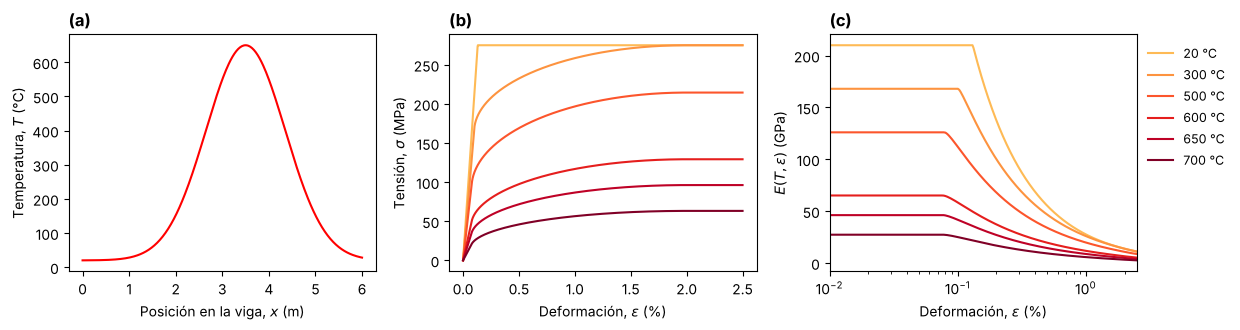

In [ ]:
import viga_fuego as vf

x = np.linspace(0, vf.L, 301)                   # posición en la viga (m)
eps = np.linspace(1e-6, 0.025, 1000)            # deformación (adimensional)

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(x, vf.T_x(x), 'r')
ax[0].set_xlabel('Posición en la viga, $x$ (m)'); ax[0].set_ylabel('Temperatura, $T$ (°C)')
for T, color in zip([20, 300, 500, 600, 650, 700], plt.cm.YlOrRd(np.linspace(0.35, 1, 6))):
    E = vf.E_T(T, eps)                          # módulo de elasticidad (Pa)
    ax[1].plot(eps*100, E*eps/1e6, color=color)                       # sigma = E eps
    ax[2].plot(eps*100, E/1e9, color=color, label=f'{T} °C')
ax[1].set_xlabel(r'Deformación, $\varepsilon$ (%)'); ax[1].set_ylabel(r'Tensión, $\sigma$ (MPa)')
ax[2].set_xscale('log'); ax[2].set_xlim(0.01, 2.5)
ax[2].set_xlabel(r'Deformación, $\varepsilon$ (%)'); ax[2].set_ylabel(r'$E(T, \varepsilon)$ (GPa)')
ax[2].legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1, 1))
for axis, label in zip(ax, ['(a)', '(b)', '(c)']):
    axis.set_title(label, loc='left', fontweight='bold')     # etiqueta sobre la esquina superior izquierda
plt.tight_layout(); plt.show()

Como muestra la figura: **(a)** la zona más caliente de la viga está entre $x = 3$ y $4$ m, medidos desde el empotramiento. **(b)** Para deformaciones pequeñas, $\sigma$ es proporcional a $\varepsilon$ y el acero se comporta en forma elástica. Para deformaciones mayores, la curva $\sigma(\varepsilon)$ se aplana: el acero se ablanda y la viga se deforma más. A mayor temperatura, este cambio ocurre con una deformación y una tensión menores. **(c)** En consecuencia, $E$ es constante mientras el acero está en su rango proporcional, cuyo límite depende de la temperatura, y luego disminuye con la deformación. El modelo evalúa $E$ con la deformación de la fibra más exigida, lo que es una simplificación conservadora.

### (a) 0.4 pts — Planteamiento

📝 Escriba el problema como dos EDOs de 2° orden, una para $M(x)$ y otra para $y(x)$, con sus condiciones de borde.

Luego, explique por qué las EDOs de $M$ y $y$ deben resolverse **simultáneamente**, y por qué este no es el caso para una viga simplemente apoyada en ambos extremos.

**Respuesta (a).**

### (b) 0.6 pts — Viga sin incendio

Considere la viga sin incendio, con un módulo de elasticidad constante, $E = E_{20}$, y una carga $q = 20$ kN/m.

📝 Indique si, en este caso, la EDO de $y$ es lineal o no lineal, y justifique.

Luego, resuelva el problema por diferencias finitas de orden $O(\Delta x^2)$ y valide su solución con la solución exacta,

\begin{equation*}
y(x) = -\frac{q\,x^2(L - x)(3L - 2x)}{48\,E_{20}I}.
\end{equation*}

Grafique en escala log-log el error nodal máximo, $\max_i |y_i - y(x_i)|$, en función de $\Delta x$, para $N = 11, 21, 41, 81, 161, 321$ nodos, y calcule la pendiente.

**Respuesta (b).**

In [ ]:
# (b)


### (c) 0.6 pts — Viga en el incendio

Resuelva el problema de la viga en el incendio, con $E\big(T(x), \varepsilon\big)$, para $q = 20$ kN/m y $N = 121$ nodos. Compare en un gráfico su deflexión con la de la viga sin incendio de (b), y reporte $y_{\min}$ y $M(0)$.

In [ ]:
# (c)


### (d) 0.3 pts — Reacciones en los apoyos

Para la solución de (c), calcule la reacción del pilar, $R_B = -V(L)$, y la reacción vertical del muro, $R_A = V(0)$, ambas positivas hacia arriba, donde $V = dM/dx$ es el esfuerzo de corte. Use derivadas numéricas de orden $O(\Delta x^2)$ y verifique el equilibrio, $R_A + R_B = qL$.

In [ ]:
# (d)


### (e) 0.6 pts — Método del disparo

📝 Plantee el problema de (c) para resolverlo por el método del disparo. Luego, resuélvalo, compare $y_{\min}$ y $M(0)$ con (c), y mida el tiempo de cálculo.

**Respuesta (e).**

In [ ]:
# (e)


### (f) 0.5 pts — `solve_bvp` y comparación de métodos

Resuelva el problema de (c) con `solve_bvp`. Reporte $y_{\min}$, $M(0)$, el número de nodos de la malla final y el tiempo de cálculo.

Luego, construya una tabla que compare los tres métodos (diferencias finitas, disparo y `solve_bvp`), con columnas: $y_{\min}$ (mm), $M(0)$ (kN m) y tiempo (s).

📝 Compare los tres métodos en este problema: costo de cálculo y dificultades de implementación.

In [ ]:
# (f)


**Respuesta (f).**

---
## Problema 2 (3.0 puntos) — El gol de Roberto Carlos

### Contexto

El 3 de junio de 1997, en el Torneo de Francia, Roberto Carlos ejecutó un tiro libre a unos 35 m del arco francés. El balón salió con una rapidez estimada en 38 m/s (unos 136 km/h) y una rotación de unos 88 rad/s. Pasó por fuera de la barrera, parecía irse lejos del arco por la derecha, y en los últimos metros se curvó hacia adentro y entró junto al poste. Durante años se discutió si fue suerte. En 2010, Dupeux, Le Goff, Quéré y Clanet (*New J. Phys.* **12**, 093004) mostraron que la curva final es una consecuencia de la física del problema: a medida que el arrastre frena el balón, la fuerza de Magnus gana importancia relativa y la trayectoria se cierra en una espiral.

En este problema modelaremos el tiro, analizaremos los métodos para resolverlo y, al final, invertiremos la pregunta: **¿cómo hay que patear para que el balón entre donde uno quiere?**


### Modelo

Usamos un sistema cartesiano con origen en el punto del tiro: $x$ apunta hacia el arco, $y$ es lateral (positivo hacia la izquierda del pateador) y $z$ es vertical. La línea de gol está en $x = d = 35$ m, el arco está centrado en $y = 0$ y mide 7.32 m de ancho y 2.44 m de alto. La barrera está a 9.15 m.

<center><img src="images/tiro_esquema.png" width="800"></center>

<p style="max-width:800px; margin:0 auto; text-align:justify;"><small><b>Figura 2.</b> Esquema del tiro libre. Sistema de coordenadas, las dimensiones de la cancha, la barrera y el arco, y los ángulos de elevación $\alpha$ y azimut $\beta$ con que sale el balón: <strong>(a)</strong> vista superior, <strong>(b)</strong> vista lateral y <strong>(c)</strong> el arco visto desde el pateador, con el punto objetivo del ítem (d).</small></p>

La segunda ley de Newton para el balón es:

\begin{equation*}
m\frac{d\vec{V}}{dt} = -mg\,\hat{z} + \vec{F}_D + \vec{F}_M, \qquad \frac{d\vec{r}}{dt} = \vec{V},
\end{equation*}

con la fuerza de arrastre y la fuerza de Magnus:

\begin{equation*}
\vec{F}_D = -\frac{1}{2}\rho A\,C_D\,\lvert\vec{V}\rvert\,\vec{V}, \qquad
\vec{F}_M = \frac{1}{2}\rho A\,C_L\,\lvert\vec{V}\rvert^2\left(\hat{\omega}\times\hat{V}\right),
\end{equation*}

donde $\vec{\omega}$ es la velocidad angular del balón, $\hat{\omega} = \vec{\omega}/\lvert\vec{\omega}\rvert$, $\hat{V} = \vec{V}/\lvert\vec{V}\rvert$ y $A = \pi R^2$. Supondremos que $\vec{\omega}$ es constante durante el vuelo.

Los coeficientes $C_D$ y $C_L$ dependen del número de Reynolds, $\mathrm{Re} = 2R\lvert\vec{V}\rvert/\nu$, y del parámetro de rotación, $S_p = R\lvert\vec{\omega}\rvert/\lvert\vec{V}\rvert$. Los valores medidos en túnel de viento por Asai et al. (*Sports Eng.* **10**, 101, 2007) y en trayectorias por Goff y Carré (*Eur. J. Phys.* **31**, 775, 2010) están en la carpeta `datos/`:
- `CD_balon_Re.csv`: $C_D$ de un balón **sin rotación** en función de $\mathrm{Re}$;
- `CD_balon_Sp.csv`: $C_D$ de un balón **con rotación** en función de $S_p$ (régimen de alta velocidad);
- `CL_balon_Sp.csv`: $C_L$ en función de $S_p$.

Use $C_D(\mathrm{Re})$ si $\vec{\omega} = 0$ y $C_D(S_p)$ si el balón gira. Sin rotación, $C_L = 0$.

Parámetros: $m = 0.436$ kg, $R = 0.1093$ m, $\rho = 1.2$ kg/m³, $\nu = 1.5\times10^{-5}$ m²/s y $g = 9.8$ m/s².

El archivo `animacion_tiro.py` contiene la función `animar_tiro(t, x, y, z, ...)`, que genera una animación 3D de la trayectoria. Permite reproducir, pausar y retroceder, y cambiar la cámara (pateador, arquero, vista superior, lateral). Revise su documentación con `help`.

In [16]:
import animacion_tiro as at
m, R, rho, nu, g = 0.436, 0.1093, 1.2, 1.5e-5, 9.8
A = np.pi*R**2
d_arco = 35.0                                   # m
barrera = dict(x=9.15, y=[-2.2, -1.6, -1.0, -0.4], altura=1.85)

### (a) 0.7 pts — Coeficientes aerodinámicos y modelo

**(a.1)** Cargue las tres tablas y construya las funciones `CD(V, Sp)` y `CL(Sp)`, donde `V` es la rapidez $\lvert\vec{V}\rvert$ en m/s, con *splines* cúbicos naturales (Unidad 4). Fuera del rango de cada tabla, extrapole con la recta tangente al spline en el extremo. Para $C_L$, agregue el punto $(S_p, C_L) = (0, 0)$. Grafique los datos y sus interpolantes, con $\mathrm{Re}$ hasta $6\times10^5$ y $S_p$ hasta 0.5.

**(a.2)** Programe la función `F(t, u, w, rho=1.2)` del sistema $\frac{d\vec{u}}{dt} = \vec{F}(t, \vec{u})$, con $\vec{u} = (x, y, z, V_x, V_y, V_z)$ y `w` el vector $\vec{\omega}$ (rad/s). Valídela sin aire (`rho=0`): resuelva el tiro con $\vec{V}_0 = (35.1, -10.1, 10.5)$ m/s y compare la posición en $t = 1$ s con la solución analítica del movimiento parabólico.

**(a.3)** 📝 Calcule el rango de $\mathrm{Re}$ y de $S_p$ que recorre el tiro de Roberto Carlos, con $\vec{V}_0 = (35.1, -10.1, 10.5)$ m/s y $\vec{\omega} = (0, 0, 88)$ rad/s, y compárelo con el rango de las tablas. ¿Qué hace su interpolante fuera de ese rango? ¿Por qué es preferible extrapolar con la recta tangente que con el polinomio cúbico del último tramo del spline?

In [17]:
# (a.1)


In [18]:
# (a.2)


In [19]:
# (a.3)


**Respuesta (a.3).**

### (b) 0.8 pts — Métodos de paso fijo

**(b.1)** Programe una función `paso_fijo(F, t_span, u0, h, metodo, args=())` que resuelva un sistema de EDOs con paso fijo $h$ por los métodos de Euler explícito, Heun y Runge-Kutta de 4° orden (`metodo = 'euler'`, `'heun'` o `'rk4'`). La función debe retornar `t, u` y el **número de evaluaciones de $\vec{F}$** realizadas.

**(b.2)** Para el tiro de Roberto Carlos, calcule el error en la posición en $t = 1.2$ s, $\lvert\vec{r}_h - \vec{r}_\mathrm{ref}\rvert$, para $h = 0.1/2^k$, $k = 0, \ldots, 5$, con los tres métodos. Use como referencia `solve_ivp` con `method='DOP853'`, `rtol=atol=1e-13`. Grafique el error en función de $h$ en escala log-log y calcule la pendiente de cada método.

**(b.3)** 📝 ¿Qué método y qué paso necesita para un error menor que 1 cm, y cuántas evaluaciones de $\vec{F}$ le cuesta? Compare con `solve_ivp` (RK45) con `rtol=1e-6` y `atol=1e-9`. ¿Qué método conviene y por qué?

In [20]:
# (b.1)


In [21]:
# (b.2)


In [22]:
# (b.3)


**Respuesta (b.3).**

### (c) 0.8 pts — `solve_ivp` y rigidez

**(c.1)** Resuelva el tiro de Roberto Carlos con `solve_ivp` por los métodos `RK45`, `Radau`, `BDF` y `LSODA` (`rtol=1e-6`, `atol=1e-9`). Use `events` para detectar el paso por la barrera ($x = 9.15$ m) y para detener la integración en la línea de gol. Construya una tabla con el número de pasos, el número de evaluaciones de $\vec{F}$ (`nfev`) y el tiempo de cálculo, y reporte en qué punto $(y, z)$ cruza la barrera y la línea de gol. ¿Es gol? Visualice el tiro con `at.animar_tiro`.

**(c.2)** Consideremos ahora un tiro rasante: el balón **pica** en el césped, rebota varias veces y luego rueda. Supondremos que no tiene rotación en el aire ($\vec{\omega} = 0$, así que $\vec{F}_M = 0$ y $C_D = C_D(\mathrm{Re})$). Al movimiento de (a) se agrega la fuerza de contacto con el suelo, $\vec{F}_c$, y el problema de valor inicial es:

\begin{equation*}
\frac{d\vec{r}}{dt} = \vec{V}, \qquad m\frac{d\vec{V}}{dt} = -mg\,\hat{z} + \vec{F}_D + \vec{F}_c, \qquad \vec{u}(0) = \vec{u}_0,
\end{equation*}

con $\vec{u} = (x, y, z, V_x, V_y, V_z)$. El contacto se modela como un resorte con amortiguador, que actúa solo cuando el balón penetra el césped ($z < R$):

\begin{equation*}
\vec{F}_c = \begin{cases} F_n\,\hat{z} - \mu_r F_n\,\hat{V}_h, & z < R \\ 0, & z \geq R \end{cases}, \qquad F_n = \max\left[k(R - z) - c\,V_z,\; 0\right],
\end{equation*}

donde $\hat{V}_h$ es el vector unitario de la velocidad horizontal $(V_x, V_y, 0)$ (si esta es nula, no hay roce), $k = 5.3\times10^4$ N/m, $c = 34$ N s/m y $\mu_r = 0.05$. El término $-\mu_r F_n\,\hat{V}_h$ representa en forma simplificada la resistencia a la rodadura; la rotación del balón no se modela. Como condición inicial, el centro del balón está a 0.5 m sobre el césped y el balón avanza a 10 m/s mientras baja a 3 m/s: $\vec{u}_0 = (0, 0, R + 0.5, 10, 0, -3)$.

Programe la función `F_cesped(t, u)`, que evalúa el lado derecho del PVI incluyendo $\vec{F}_c$, y resuelva la EDO para los primeros 8 s de movimiento con los mismos cuatro métodos. Construya la tabla de (c.1). En dos gráficos lado a lado, grafique en función del tiempo: (i) la altura del balón sobre el césped, $z - R$, y (ii) el paso de tiempo de cada método, `np.diff(sol.t)`, con escala logarítmica en el eje vertical.

**(c.3)** 📝 En (c.2), el balón pica varias veces y desde $t \approx 2.2$ s rueda y se frena lentamente. ¿Por qué RK45 agranda su paso de tiempo entre dos piques, pero no lo hace mientras el balón rueda, a diferencia de Radau y BDF? Compare con (c.1) y explique qué hace que un problema sea rígido.

In [23]:
# (c.1)


In [24]:
# (c.2)


**Respuesta (c.3).**

### (d) 0.7 pts — Encontrar el tiro

Ahora invertimos la pregunta: el balón debe entrar en el punto $(x, y, z) = (35, -3.16, 1.0)$ m, a 0.5 m del poste derecho y a 1 m de altura.

**(d.1)** Con $\lvert\vec{V}_0\rvert = 38$ m/s y $\vec{\omega} = (0, 0, 88)$ rad/s, encuentre el ángulo de elevación $\alpha$ y el azimut $\beta$ del tiro, donde $\vec{V}_0 = \lvert\vec{V}_0\rvert(\cos\alpha\cos\beta,\ \cos\alpha\sin\beta,\ \sin\alpha)$. Reporte $\alpha$, $\beta$, el tiempo de vuelo, la rapidez con que el balón llega al arco y el punto donde pasa la barrera. Visualice el tiro con `at.animar_tiro`.

**(d.2)** 📝 En los ítems (a) a (c), el tiro se resolvió conociendo la posición y la velocidad iniciales. ¿Qué tipo de problema es el de (d.1), y por qué? Indique qué condiciones se imponen y en qué instantes, y relacione el método que usó en (d.1) con los métodos de la Unidad 10.

In [25]:
# (d.1)


**Respuesta (d.2).**